# momentum_solve 이벤트별 확장성 — 이벤트마다 막대, 이벤트마다 scaling

`apps/rbc_nob/scalability/out/scal_<mode>_<n>_np<N>/phase_timing_<hw>_<job>_r<rep>.csv` 중 **momentum 세부 구간**(`momentum.<dU|dV|dW>.<호출>`,
`momentum.post.*`)이 있는 런만 읽는다 (꼬리표 `h200m`·`v100m`, 그리고 새 바이너리로 돈 A100 잡). 반복 중 `step_total` 중앙값 런을 대표로 쓴다.

- **이벤트** = momentum_solve 가 부르는 호출 하나. 기본은 세 성분(dU·dV·dW)을 **합친** 17 이벤트, §2 는 성분별로 따로.
- 막대 그림: x = 이벤트, 막대 = np (1·2·4·8, 파란색 명도 순서 — 같은 양의 크기 비교라 순차 색).
- scaling 그림: 이벤트마다 패널 하나, 시간 vs np (log-log) + 이상선(strong 1/np, weak 평평), 색 = 하드웨어.
- 효율표: 이벤트별 $E(np)$ — strong $T_1/(np\,T_{np})$, weak $T_1/T_{np}$.

구간 정의는 `docs/Scalability/plan.md` §1·§2, 해석은 `docs/Scalability/ranking_20261017.md` §4b.

In [ ]:
import csv, glob, os, re
from collections import defaultdict
import numpy as np
import matplotlib
try:
    get_ipython().run_line_magic("matplotlib", "inline")
except NameError:
    matplotlib.use("Agg")
import matplotlib.pyplot as plt
from matplotlib.ticker import FixedLocator, NullFormatter, PercentFormatter
plt.rcParams.update({"figure.dpi": 110, "font.size": 9, "legend.fontsize": 8, "axes.grid": True, "grid.alpha": 0.25,
                     "axes.spines.top": False, "axes.spines.right": False})
OUT_DIR = os.path.abspath(os.path.join(os.getcwd(), "..", "scalability", "out"))
SAVE_FIG = False

HW = {"h200": ("H200", "#2a78d6"), "a100": ("A100", "#eb6834"), "v100": ("V100", "#1baf7a")}   # 하드웨어 = 색 (검증된 슬롯 1–3)
NP_COLOR = {1: "#bcd3f0", 2: "#7fa9e3", 4: "#2a78d6", 8: "#164a8a"}                          # np = 파란색 순차 명도
COMPONENTS = ["dU", "dV", "dW"]
# 이벤트 (호출) — 성분 공통 12 + 사후 5. 이름은 CSV 의 구간 이름 꼬리와 같다.
EVENTS_PER_COMPONENT = ["build_x", "tdma_x", "scatter_x", "build_y", "tdma_y", "scatter_y",
                        "build_z", "tdma_z", "scatter_z", "halo", "wall_ghost", "couple_rhs"]
EVENTS_POST = ["block_couple_v", "halo_dV", "wall_ghost_dV", "block_couple_u", "add_increment"]
EVENTS = EVENTS_PER_COMPONENT + EVENTS_POST

def load_runs(out_dir=OUT_DIR):
    runs = defaultdict(list)
    for path in sorted(glob.glob(os.path.join(out_dir, "scal_*", "phase_timing_*.csv"))):
        m = re.search(r"scal_(strong|weak)_(\d+)_np(\d+)/phase_timing_([a-z0-9]+)_(\d+)_r(\d+)\.csv$", path)
        if not m:
            continue
        ph = {}
        with open(path) as fh:
            for row in csv.reader(l for l in fh if not l.startswith("#")):
                if row[0] != "phase":
                    ph[row[0]] = float(row[3])           # 랭크 max ms/step
        if not any(n.startswith("momentum.") for n in ph):
            continue                                     # momentum 세부 구간이 없는(구 바이너리) 런은 제외
        hw = m.group(4).rstrip("m")                      # h200m → h200
        runs[(hw, m.group(1), int(m.group(2)), int(m.group(3)))].append(ph)
    return runs

runs = load_runs()
cases = {k: sorted(v, key=lambda r: r["step_total"])[len(v) // 2] for k, v in runs.items()}

def event_time(ph, event, component=None):
    """이벤트 ms/step. component None → 세 성분 합 (post 이벤트는 성분이 없다)."""
    if event in EVENTS_POST:
        return ph.get(f"momentum.post.{event}", 0.0)
    comps = [component] if component else COMPONENTS
    return sum(ph.get(f"momentum.{c}.{event}", 0.0) for c in comps)

print(f"{len(cases)} cases with momentum breakdown")
for k in sorted(cases):
    print(f"  {k[0]:5s} {k[1]:6s} {k[2]}^3 np{k[3]:<2d}  step_total {cases[k]['step_total']:7.1f}  momentum_solve {cases[k]['momentum_solve']:6.1f} ms/step  (x{len(runs[k])})")

15 cases with momentum breakdown
  h200  strong 256^3 np1   step_total    41.7  momentum_solve   19.7 ms/step  (x2)
  h200  strong 256^3 np2   step_total    26.2  momentum_solve   13.2 ms/step  (x2)
  h200  strong 256^3 np4   step_total    17.3  momentum_solve    9.2 ms/step  (x2)
  h200  strong 512^3 np1   step_total   329.2  momentum_solve  159.2 ms/step  (x2)
  h200  strong 512^3 np2   step_total   172.8  momentum_solve   85.1 ms/step  (x2)
  h200  strong 512^3 np4   step_total    91.5  momentum_solve   46.4 ms/step  (x2)
  h200  weak   256^3 np1   step_total    41.7  momentum_solve   19.7 ms/step  (x2)
  h200  weak   256^3 np2   step_total    44.4  momentum_solve   21.4 ms/step  (x2)
  h200  weak   256^3 np4   step_total    44.6  momentum_solve   21.6 ms/step  (x2)
  v100  strong 256^3 np1   step_total   198.1  momentum_solve  113.3 ms/step  (x2)
  v100  strong 256^3 np2   step_total    95.6  momentum_solve   54.9 ms/step  (x2)
  v100  strong 256^3 np4   step_total    53.2  momentu

## 1. 이벤트별 막대 — np 를 나란히 (성분 합)

이벤트 하나에 np 수만큼 막대. strong 이면 막대가 np 에 반비례로 짧아져야 하고, weak 이면 같은 높이여야 한다.
막대 위 숫자는 np 1 대비 비율 (strong 은 이상값 1/np 와 비교).

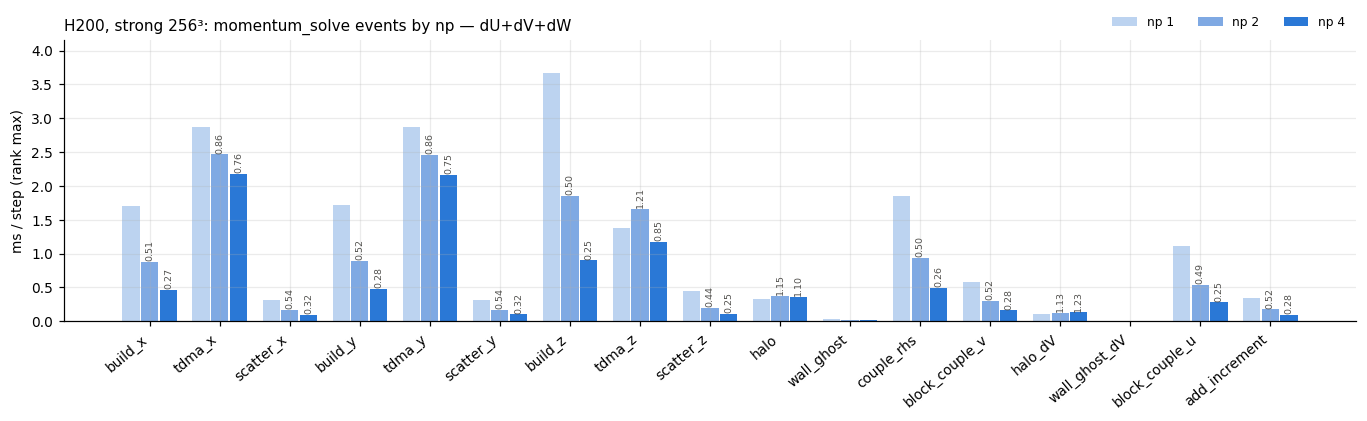

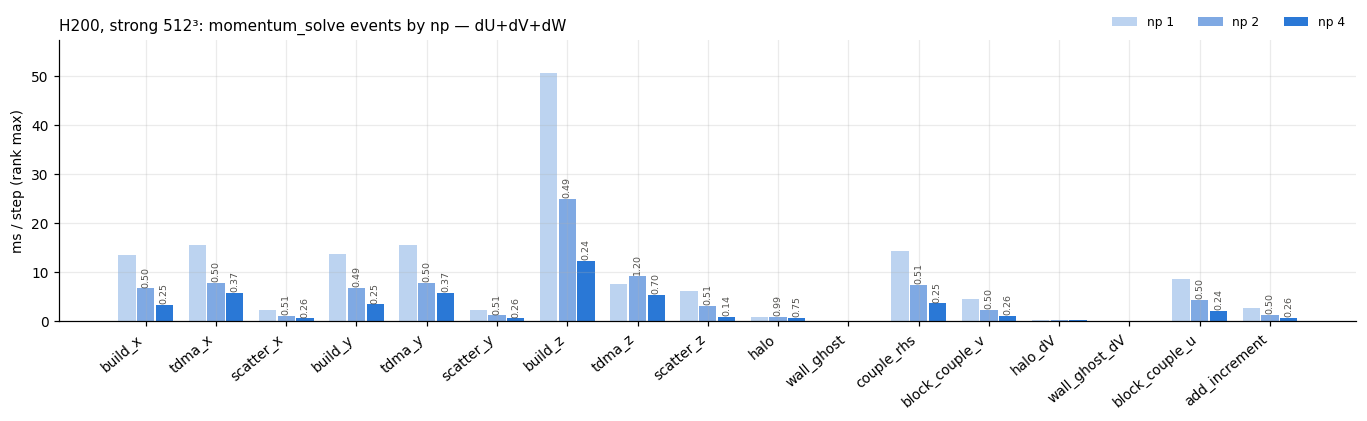

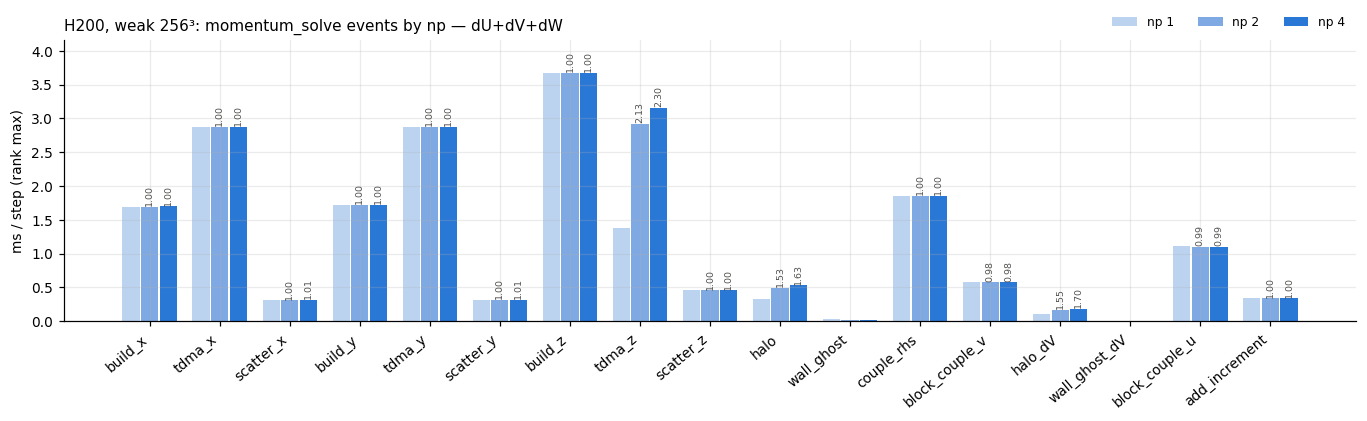

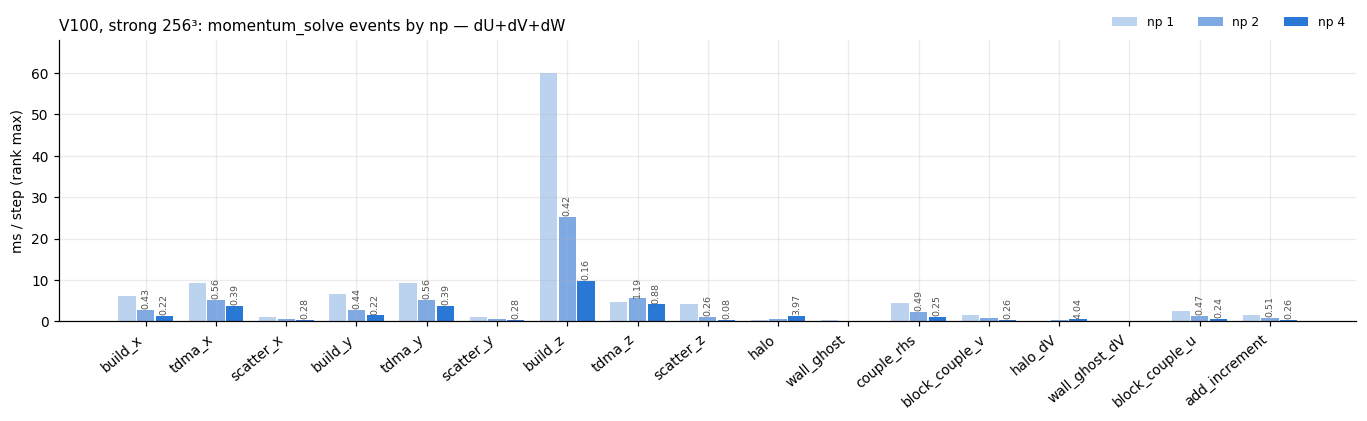

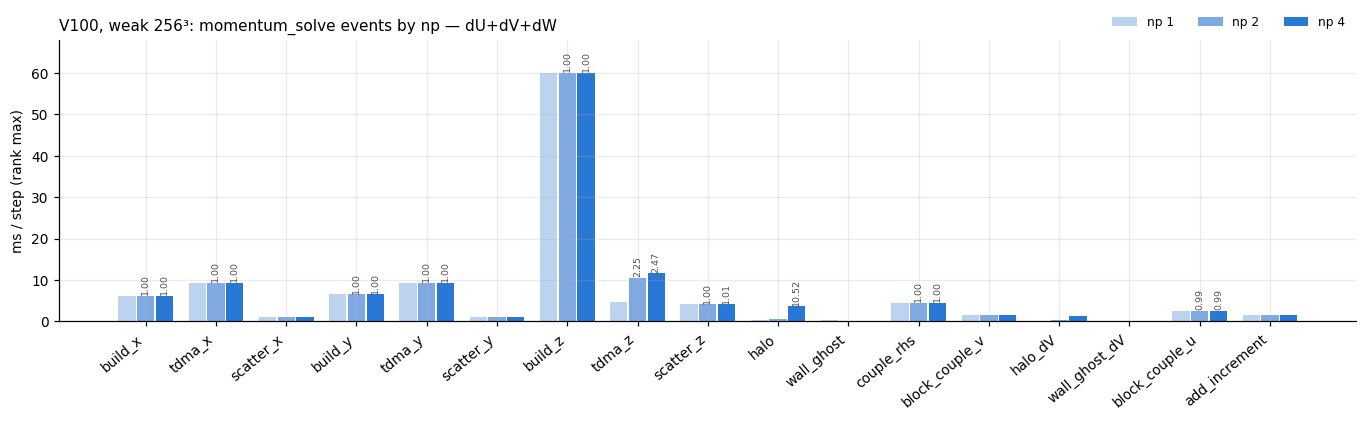

In [ ]:
def plot_event_bars(mode, hw, n, component=None, ax=None, fname=None):
    keys = sorted(k for k in cases if k[:3] == (hw, mode, n))
    if not keys:
        return None
    own = ax is None
    if own:
        fig, ax = plt.subplots(figsize=(12.5, 3.9))
    nps = [k[3] for k in keys]
    events = EVENTS if component is None else EVENTS_PER_COMPONENT
    xs = np.arange(len(events)); width = 0.8 / len(nps)
    for j, k in enumerate(keys):
        vals = np.array([event_time(cases[k], e, component) for e in events])
        pos = xs - 0.4 + width * (j + 0.5)
        ax.bar(pos, vals, width * 0.92, color=NP_COLOR.get(k[3], "#164a8a"), label=f"np {k[3]}")
        if j > 0:
            base = np.array([event_time(cases[keys[0]], e, component) for e in events])
            ratio = np.divide(vals, base, out=np.zeros_like(vals), where=base > 0)
            for x, v, r in zip(pos, vals, ratio):
                if v > 0.03 * vals.max():
                    ax.annotate(f"{r:.2f}", (x, v), xytext=(0, 2), textcoords="offset points", ha="center", fontsize=6.2, color="#52514e", rotation=90)
    ax.set_xticks(xs); ax.set_xticklabels(events, rotation=40, ha="right")
    ax.set_ylabel("ms / step (rank max)")
    comp = f" — {component}" if component else " — dU+dV+dW"
    ax.set_title(f"{HW[hw][0]}, {mode} {n}³: momentum_solve events by np{comp}", fontsize=10, loc="left")
    ax.set_ylim(0, ax.get_ylim()[1] * 1.08)
    ax.legend(frameon=False, ncol=len(nps), loc="lower right", bbox_to_anchor=(1.0, 1.0))   # 축 위 오른쪽 — 막대와 안 겹친다
    if own:
        plt.tight_layout()
        if SAVE_FIG and fname:
            plt.gcf().savefig(fname, bbox_inches="tight")
    return ax

for hw in HW:
    for mode in ("strong", "weak"):
        for n in (256, 512):
            plot_event_bars(mode, hw, n, fname=f"momentum_events_{mode}_{hw}_{n}.png")
plt.show()

## 2. 성분별 (dU · dV · dW) 이벤트 막대

같은 그림을 성분마다. 성분 사이의 차이(예: build_z 가 dU > dV > dW, couple_rhs 는 dV·dW 만)가 보인다.

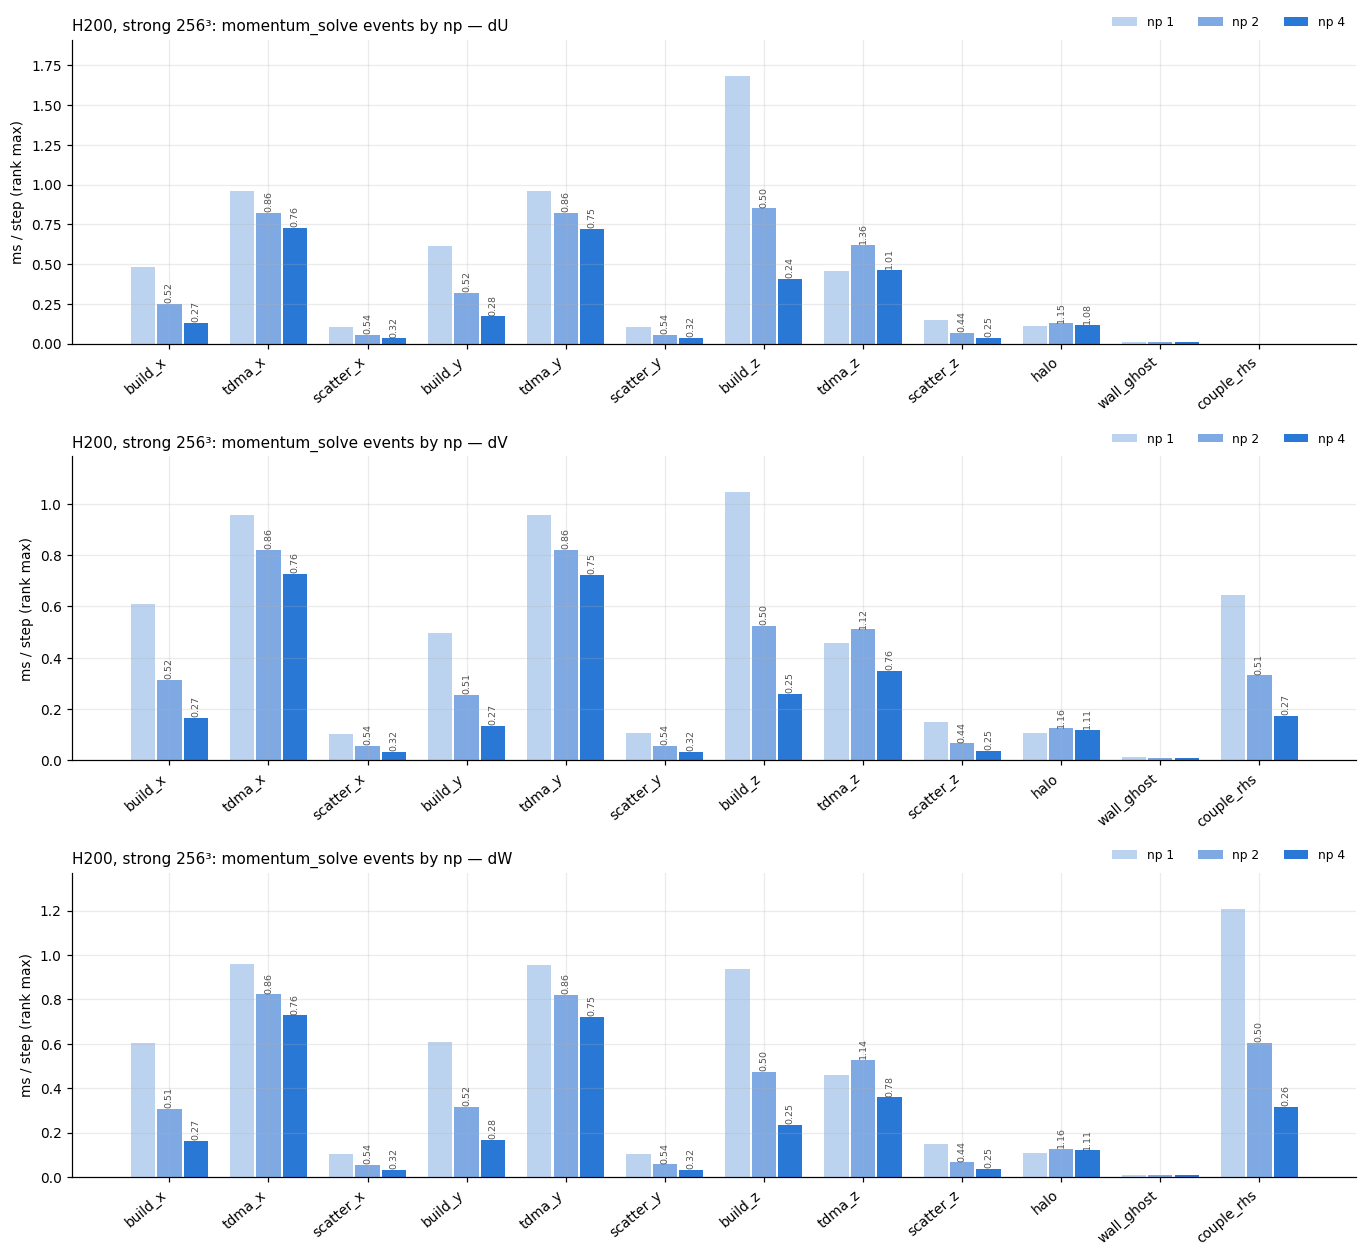

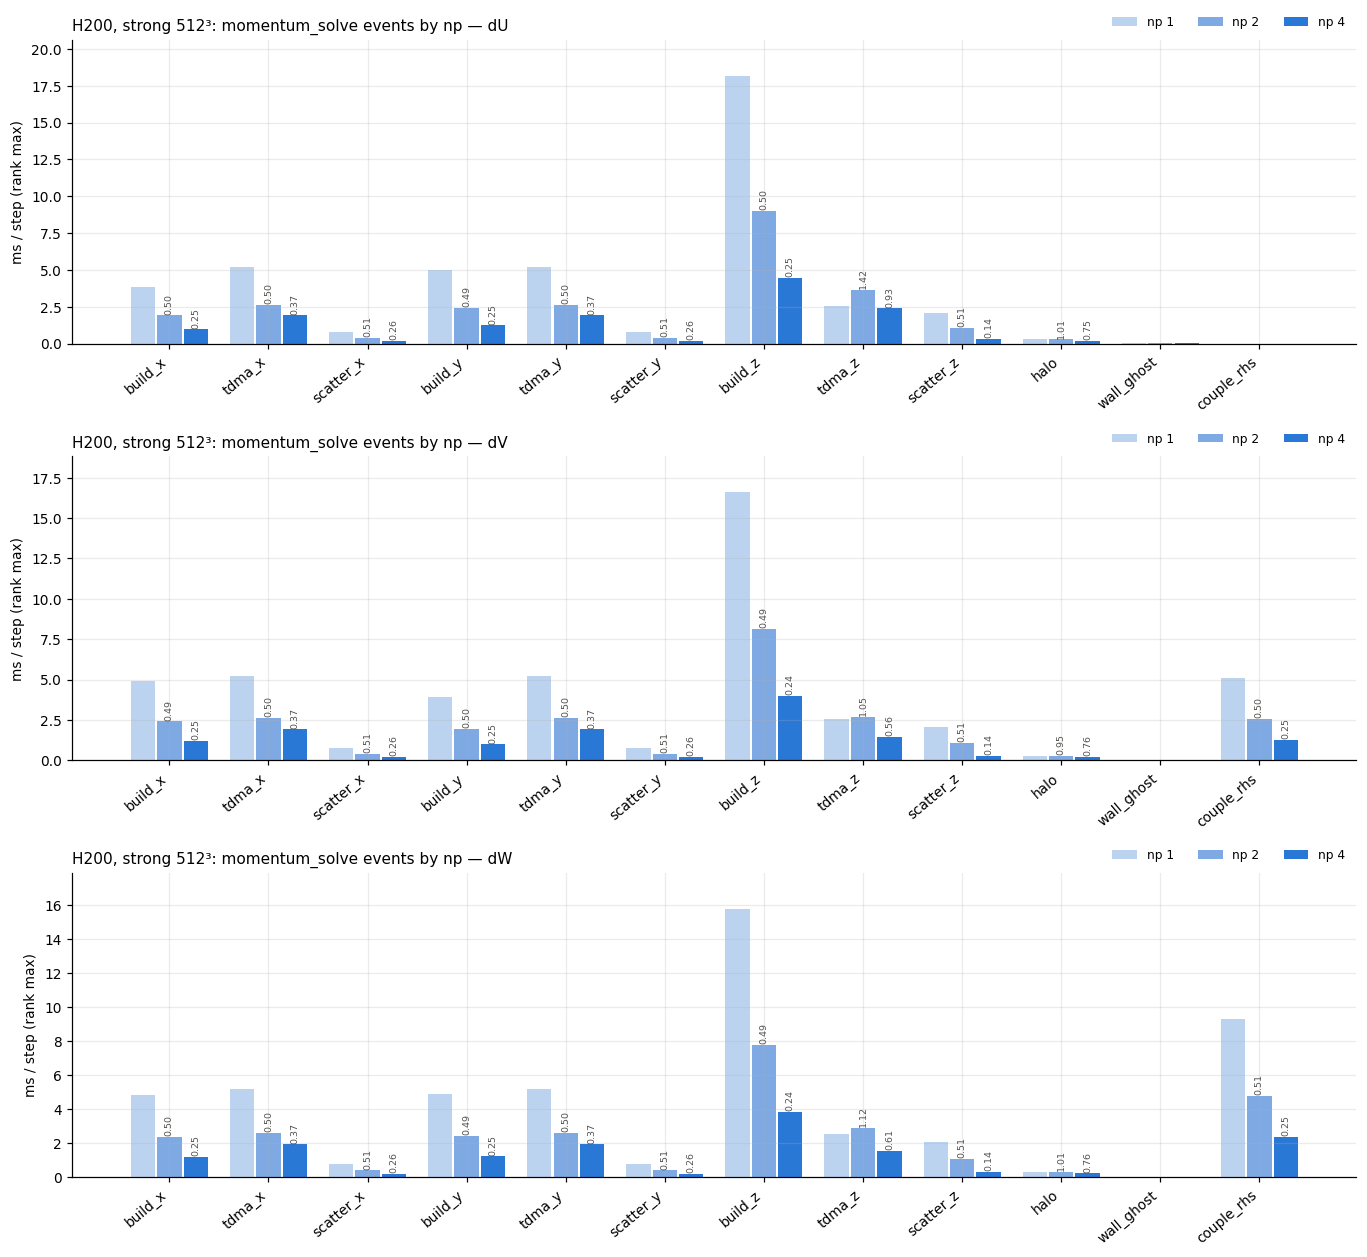

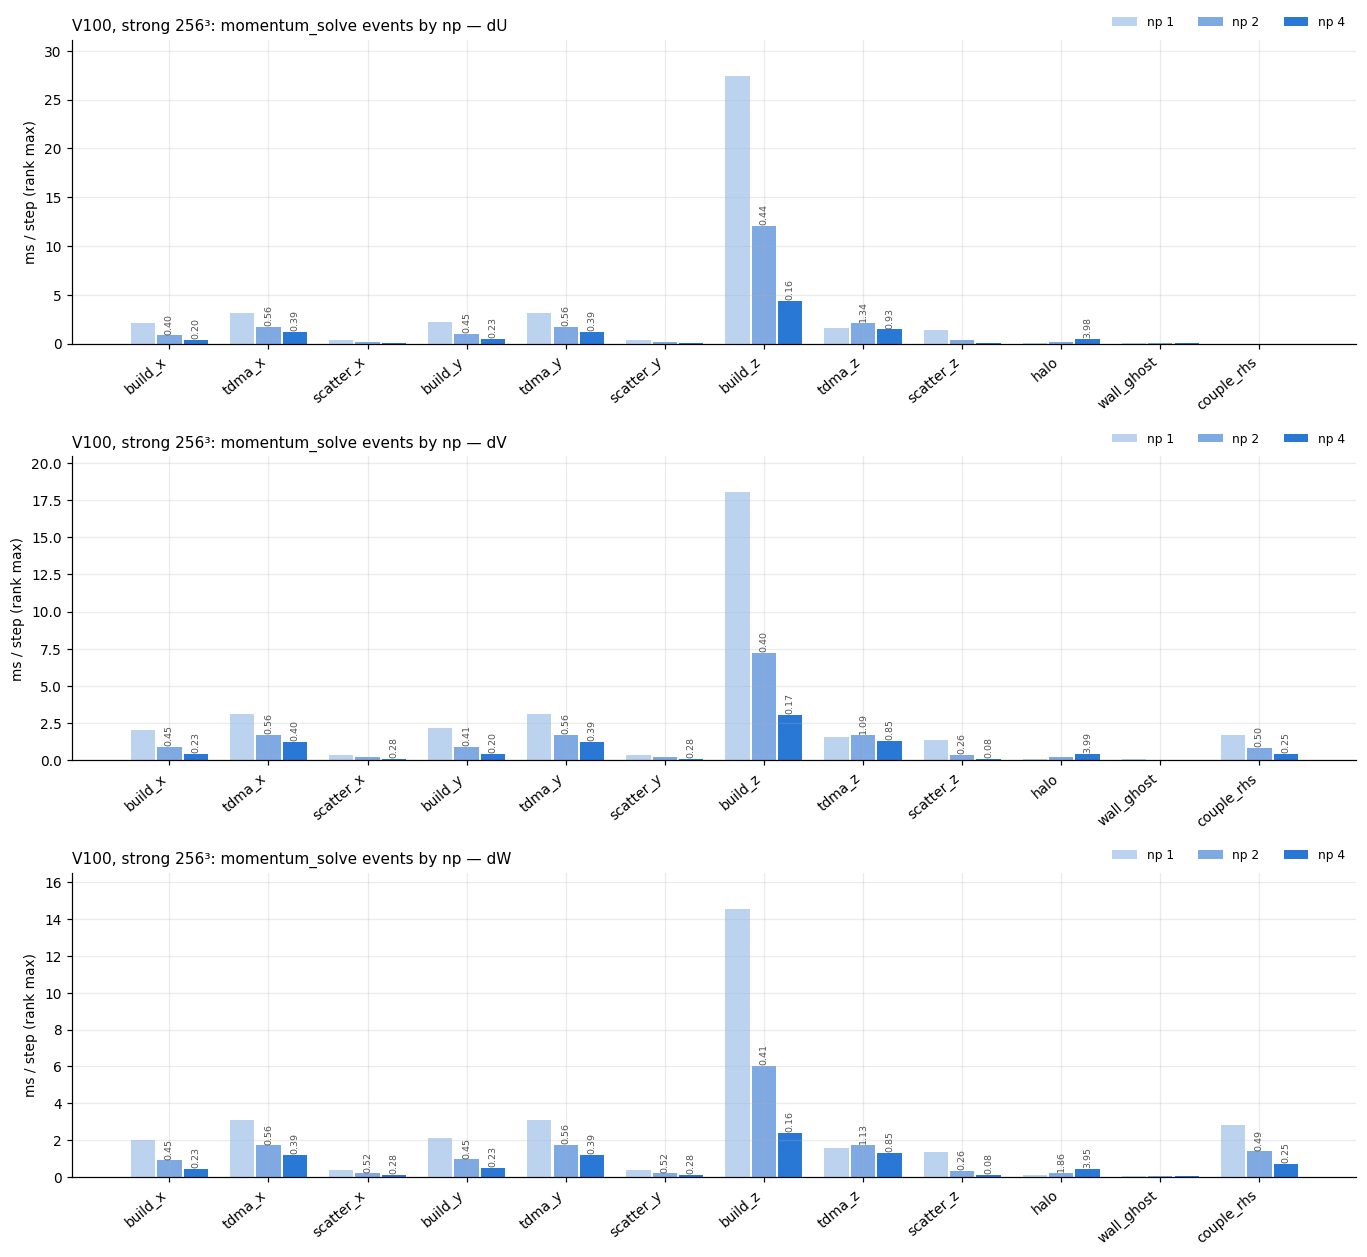

In [ ]:
for hw in HW:
    for mode in ("strong",):
        for n in (256, 512):
            keys = [k for k in cases if k[:3] == (hw, mode, n)]
            if not keys:
                continue
            fig, axes = plt.subplots(3, 1, figsize=(12.5, 11.5))   # sharex 없이 — 패널마다 이벤트 이름을 단다
            for ax, comp in zip(axes, COMPONENTS):
                plot_event_bars(mode, hw, n, component=comp, ax=ax)
            fig.tight_layout()
            if SAVE_FIG:
                fig.savefig(f"momentum_events_components_{mode}_{hw}_{n}.png", bbox_inches="tight")
plt.show()

## 3. 이벤트마다 scaling — 소형 다중 패널

패널 하나 = 이벤트 하나. 시간(ms/step, log) vs np(log₂). 회색 점선 = 이상선 (strong: $T_1/np$, weak: $T_1$). 색 = 하드웨어.
이상선에서 위로 벌어지는 패널이 확장 손실이 있는 이벤트다.

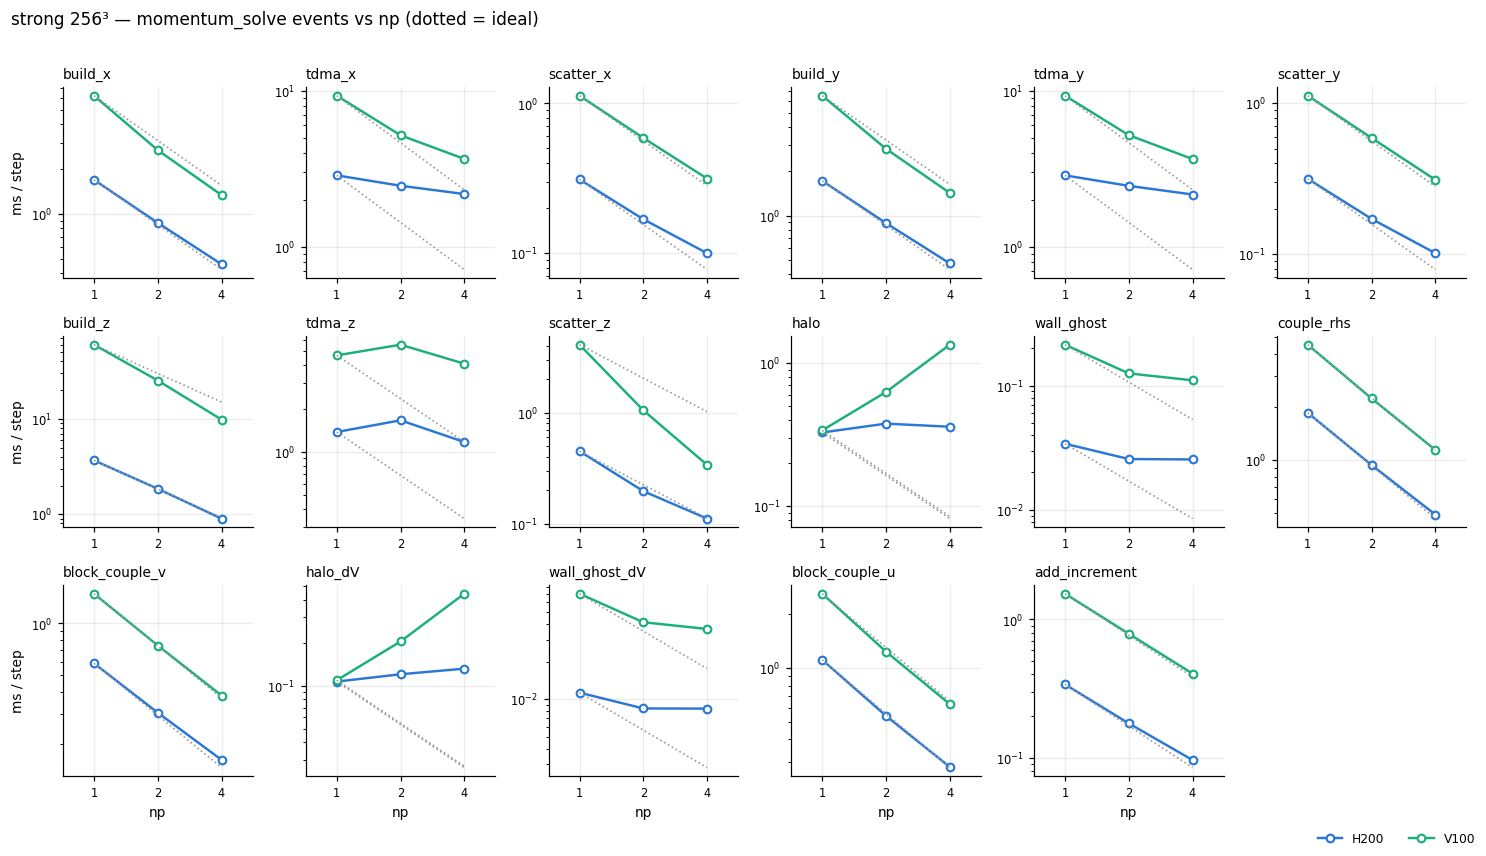

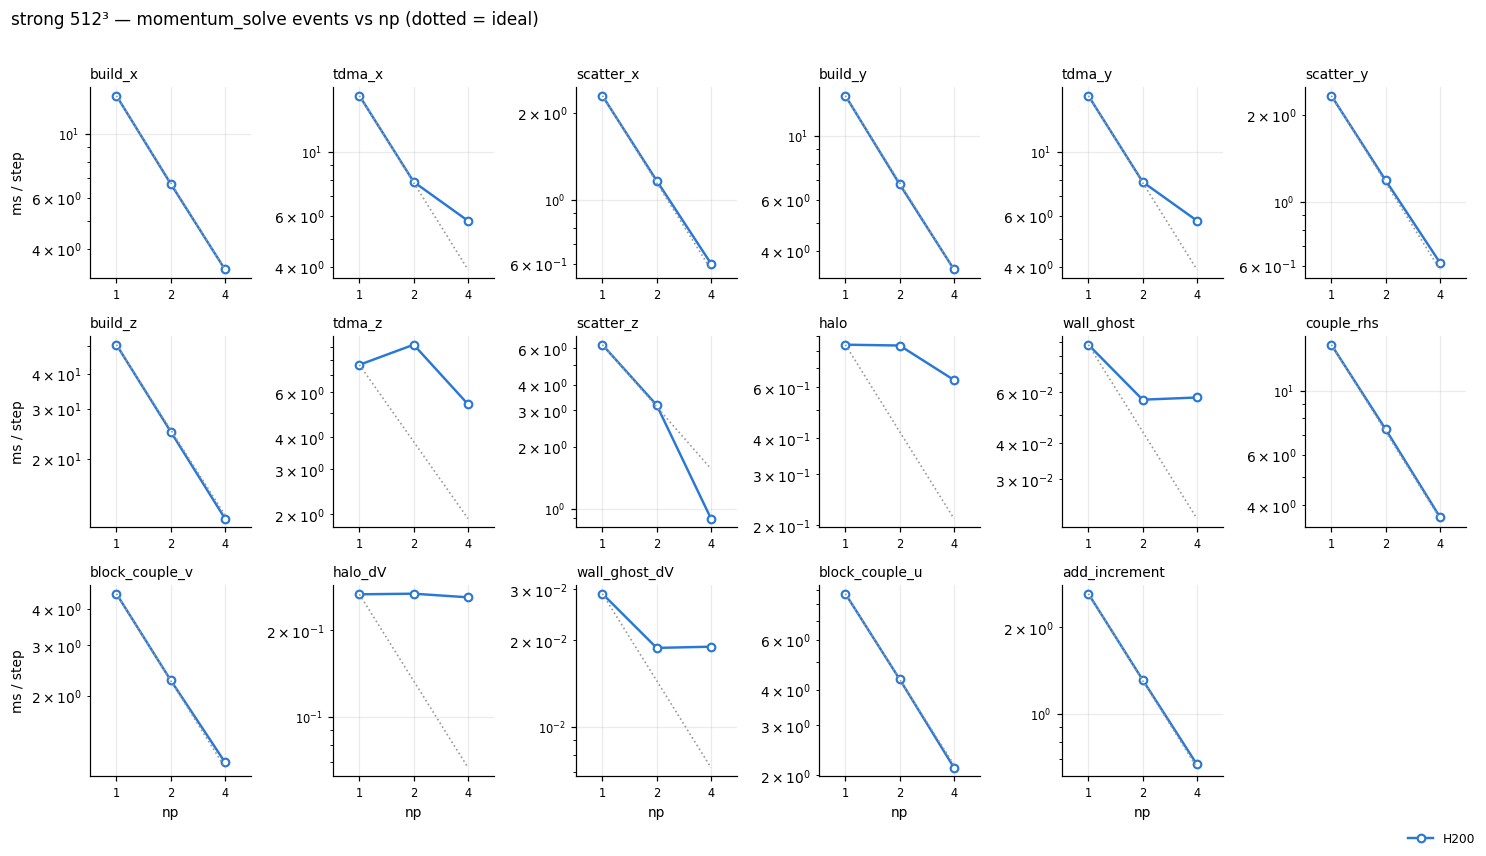

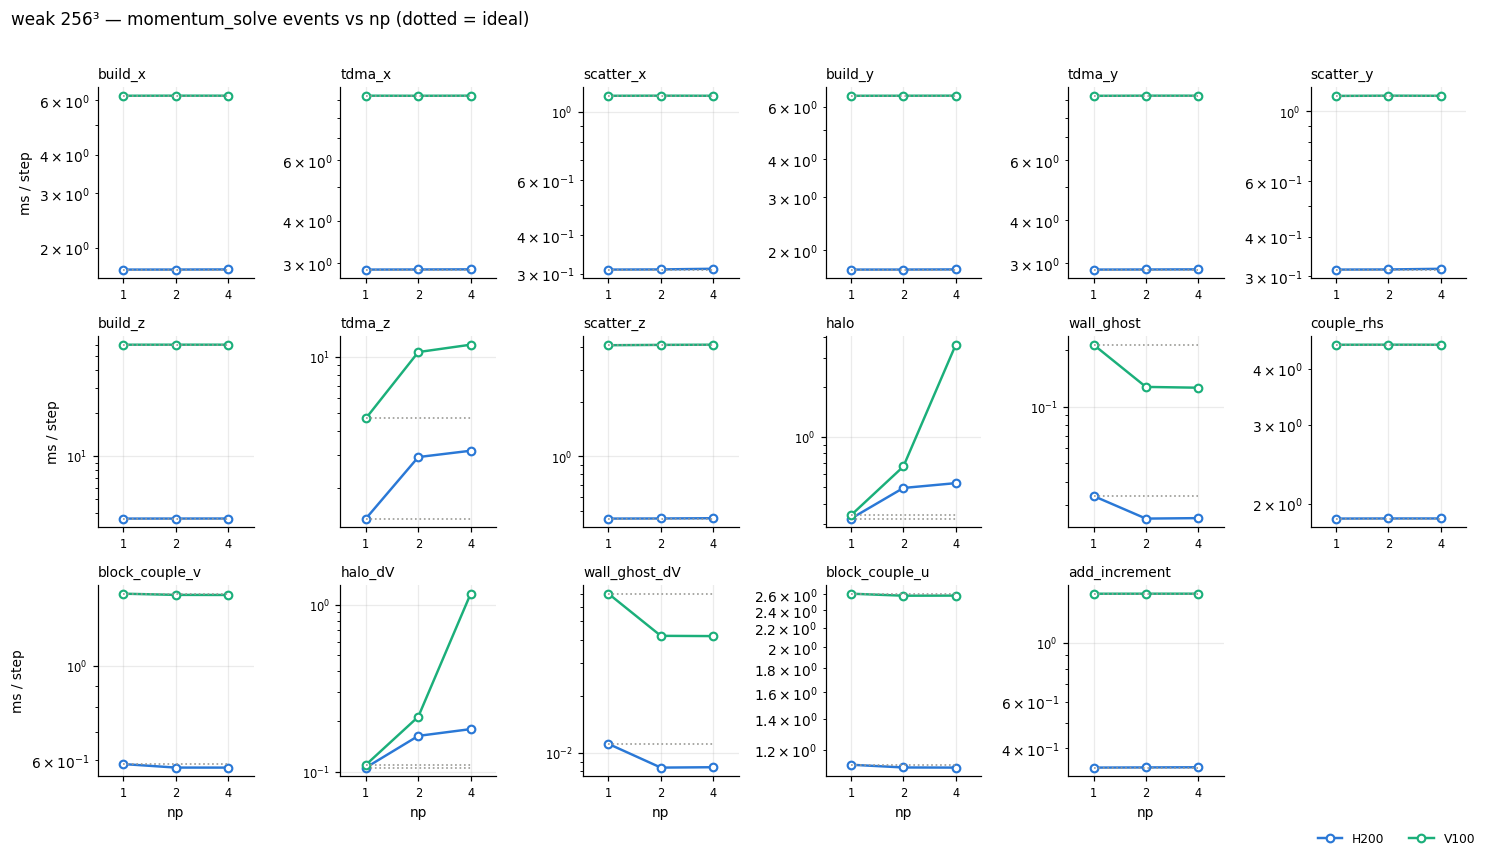

In [ ]:
def plot_event_scaling(mode, n, fname=None):
    hws = sorted({k[0] for k in cases if k[1:3] == (mode, n)})
    if not hws:
        return
    nps_all = sorted({k[3] for k in cases if k[1:3] == (mode, n)})
    ncol = 6; nrow = int(np.ceil(len(EVENTS) / ncol))
    fig, axes = plt.subplots(nrow, ncol, figsize=(13.5, 2.6 * nrow))
    for ax, e in zip(axes.flat, EVENTS):
        for hw in hws:
            keys = sorted(k for k in cases if k[:3] == (hw, mode, n))
            x = np.array([k[3] for k in keys], float); y = np.array([event_time(cases[k], e) for k in keys])
            if len(x) < 2 or y[0] <= 0:
                continue
            label, color = HW[hw]
            ax.plot(x, y, "-o", color=color, lw=1.6, ms=5, mfc="white", mew=1.4, label=label)
            ideal = y[0] * x[0] / x if mode == "strong" else np.full_like(y, y[0])
            ax.plot(x, ideal, ":", color="#9a9a96", lw=1.1)
        ax.set_xscale("log", base=2); ax.set_yscale("log")
        ax.xaxis.set_major_locator(FixedLocator(nps_all)); ax.xaxis.set_minor_formatter(NullFormatter())
        ax.set_xticklabels([str(p) for p in nps_all]); ax.set_xlim(min(nps_all) / 1.4, max(nps_all) * 1.4)
        ax.set_title(e, fontsize=9, loc="left"); ax.tick_params(labelsize=7.5)
    for ax in axes.flat[len(EVENTS):]:
        ax.axis("off")
    for ax in axes[-1]:
        ax.set_xlabel("np")
    for ax in axes[:, 0]:
        ax.set_ylabel("ms / step")
    handles, labels = axes.flat[0].get_legend_handles_labels()
    fig.legend(handles, labels, frameon=False, loc="lower right", ncol=len(labels))
    fig.suptitle(f"{mode} {n}³ — momentum_solve events vs np (dotted = ideal)", fontsize=11, x=0.01, ha="left")
    fig.tight_layout(rect=(0, 0.02, 1, 0.97))
    if SAVE_FIG and fname:
        fig.savefig(fname, bbox_inches="tight")

for mode in ("strong", "weak"):
    for n in (256, 512):
        plot_event_scaling(mode, n, fname=f"momentum_event_scaling_{mode}_{n}.png")
plt.show()

## 4. 이벤트별 효율 — 히트맵과 표

strong: $E = T_1/(np\,T_{np})$, weak: $E = T_1/T_{np}$. 100 % 보다 많이 낮은 칸이 확장 손실. 색은 한 색조의 순차 명도(낮을수록 진함).
np 1 에서 0.05 ms 미만인 이벤트(wall_ghost 류)는 잡음이라 비워 둔다.

[H200] strong 256^3 — np1 ms/step | efficiency % at np2, np4
  build_x              1.70 |    97     92
  tdma_x               2.87 |    58     33
  scatter_x            0.31 |    92     78
  build_y              1.72 |    97     91
  tdma_y               2.87 |    58     33
  scatter_y            0.31 |    92     78
  build_z              3.67 |    99    102
  tdma_z               1.38 |    41     29
  scatter_z            0.45 |   114    101
  halo                 0.33 |    43     23
  wall_ghost           0.03 |     -      -
  couple_rhs           1.85 |    99     95
  block_couple_v       0.59 |    96     90
  halo_dV              0.11 |    44     20
  wall_ghost_dV        0.01 |     -      -
  block_couple_u       1.11 |   103     99
  add_increment        0.34 |    96     88

[V100] strong 256^3 — np1 ms/step | efficiency % at np2, np4
  build_x              6.22 |   116    116
  tdma_x               9.28 |    90     63
  scatter_x            1.12 |    96     89
  build_y        

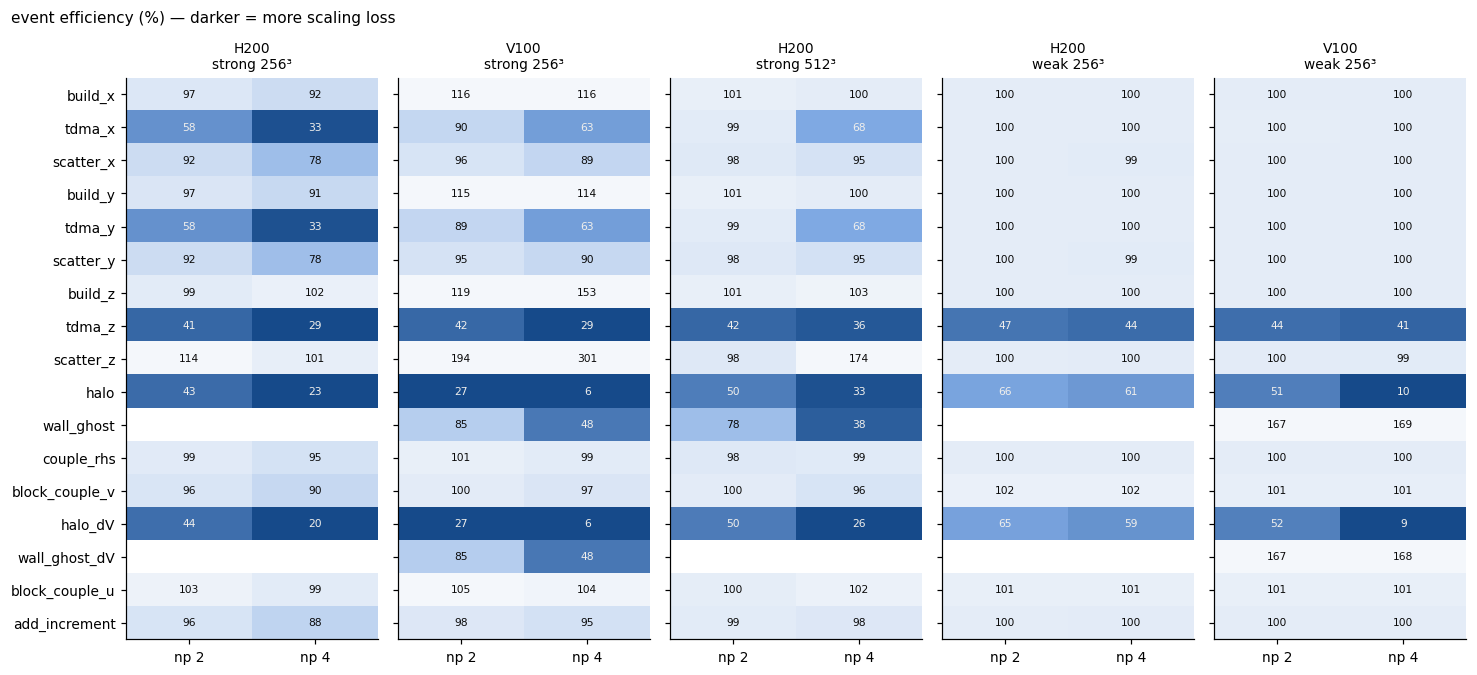

In [ ]:
from matplotlib.colors import LinearSegmentedColormap
EFF_CMAP = LinearSegmentedColormap.from_list("eff", ["#164a8a", "#7fa9e3", "#f4f7fb"])   # 낮은 효율 = 진한 파랑

def efficiency_table(mode, hw, n):
    keys = sorted(k for k in cases if k[:3] == (hw, mode, n))
    if len(keys) < 2:
        return None, None
    base = cases[keys[0]]; np0 = keys[0][3]
    rows = []
    for e in EVENTS:
        t0 = event_time(base, e)
        row = []
        for k in keys[1:]:
            t = event_time(cases[k], e)
            if t0 < 0.05 or t <= 0:          # 0.05 ms 미만 이벤트(벽 ghost 등)는 잡음이라 비운다
                row.append(np.nan); continue
            row.append(t0 / t / (k[3] / np0) if mode == "strong" else t0 / t)
        rows.append(row)
    return np.array(rows), [k[3] for k in keys[1:]]

panels = [(mode, hw, n) for mode in ("strong", "weak") for n in (256, 512) for hw in HW if efficiency_table(mode, hw, n)[0] is not None]
fig, axes = plt.subplots(1, len(panels), figsize=(2.3 * len(panels) + 2, 6.2), sharey=True)
axes = np.atleast_1d(axes)
for ax, (mode, hw, n) in zip(axes, panels):
    eff, nps = efficiency_table(mode, hw, n)
    im = ax.imshow(np.clip(eff, 0, 1.2), cmap=EFF_CMAP, vmin=0.3, vmax=1.05, aspect="auto")
    ax.set_xticks(range(len(nps))); ax.set_xticklabels([f"np {p}" for p in nps])
    ax.set_yticks(range(len(EVENTS))); ax.set_yticklabels(EVENTS)
    ax.set_title(f"{HW[hw][0]}\n{mode} {n}³", fontsize=9)
    ax.grid(False)
    for i in range(eff.shape[0]):
        for j in range(eff.shape[1]):
            if not np.isnan(eff[i, j]):
                ax.text(j, i, f"{100*eff[i, j]:.0f}", ha="center", va="center", fontsize=7, color="#f0efec" if eff[i, j] < 0.7 else "#0b0b0b")
fig.suptitle("event efficiency (%) — darker = more scaling loss", fontsize=10, x=0.01, ha="left")
fig.tight_layout()
if SAVE_FIG:
    fig.savefig("momentum_event_efficiency.png", bbox_inches="tight")
plt.show()

for mode, hw, n in panels:
    eff, nps = efficiency_table(mode, hw, n)
    print(f"[{HW[hw][0]}] {mode} {n}^3 — np1 ms/step | efficiency % at " + ", ".join(f"np{p}" for p in nps))
    base = cases[sorted(k for k in cases if k[:3] == (hw, mode, n))[0]]
    for e, row in zip(EVENTS, eff):
        print(f"  {e:16s} {event_time(base, e):8.2f} | " + "  ".join(f"{100*v:5.0f}" if not np.isnan(v) else "    -" for v in row))
    print()